# NLP Sentiment Classification on Customer Reviews

**Task 4 · TF–IDF · Multinomial Naive Bayes · Logistic Regression**

## 1. Project objective

This notebook builds a small, reproducible natural-language-processing workflow for customer review polarity. It follows the supplied task brief: ingest review records, clean and tokenize text, remove stopwords, apply lemmatization when the NLTK WordNet resource is available, transform text into a sparse TF–IDF matrix (up to 5,000 features), train **Multinomial Naive Bayes** and **Logistic Regression**, compare their out-of-fold classification metrics, and expose a `predict_sentiment()` helper for custom phrases.

### Important note about this exact CSV

The provided `sentiment_reviews.csv` has only **10 records** with 5 `positive`, 4 `negative`, and 1 `neutral` review. The brief asks for a positive/negative classifier. To avoid silently relabelling neutral as positive or negative, all ten rows are retained for data exploration, while the one neutral row is excluded from binary model fitting. The learned models therefore return only `positive` or `negative`.

Nine labelled examples are far too few for a dependable estimate of generalisation. We use **stratified 3-fold out-of-fold predictions** because this is feasible with four negative examples and five positive examples. Scores are educational smoke-test benchmarks only; they must not be presented as production performance. The 0.80 target is not asserted for this task.

### What this notebook does not claim

- It does not establish that the models generalise to unseen real-world customer populations.
- It does not support neutral sentiment prediction, because the CSV contains only one neutral example.
- It does not use external pretrained embeddings, deep-learning models, or non-recommended classifiers.

## 2. Workflow overview

1. Validate the source CSV and inspect labels, nulls, and text lengths.
2. Clean text with NLTK tokenization, stopword filtering, negation preservation, and optional WordNet lemmatization.
3. Explore review vocabulary and build fold-safe TF–IDF features.
4. Compare Multinomial Naive Bayes and Logistic Regression using stratified out-of-fold predictions.
5. Interpret confusion matrices, ROC / precision-recall curves, and model-specific token weights.
6. Fit both final pipelines on all nine binary-labelled examples and demonstrate live phrase predictions.

> **Leakage control:** TF–IDF vectorization is inside each scikit-learn `Pipeline`. Cross-validation therefore learns vocabulary and inverse-document-frequency weights only from each training fold.

## 3. Imports, project paths, and reproducibility

In [1]:
from pathlib import Path
import sys
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
    precision_recall_curve, average_precision_score
)

ROOT = Path.cwd()
if not (ROOT / "data" / "sentiment_reviews.csv").exists():
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from sentiment_pipeline import (
    ensure_nltk_resources, load_dataset, preprocess_text,
    binary_training_data, build_vectorizer, build_pipeline,
    evaluate_with_oof, save_models, predict_sentiment,
    TEXT_COLUMN, TARGET_COLUMN, ID_COLUMN, RANDOM_STATE
)

FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
MODEL_DIR = ROOT / "models"
for folder in (FIG_DIR, REPORT_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10})
print("Project root:", ROOT)

Project root: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/customer-review-sentiment-classifier-project


## 4. NLTK resource readiness

NLTK provides the tokenizer and WordNet lemmatizer. The repository runs offline using a compact fallback English stopword list and skips lemmatization if WordNet is absent. For full NLTK preprocessing, install the corpora using the commands in the README; CI downloads them before running the notebook.

In [2]:
resource_status = ensure_nltk_resources(download=False)
display(pd.DataFrame([resource_status], index=["NLTK resource availability"]))
if not resource_status["wordnet_available"]:
    print("WordNet not found: this run safely skips lemmatization. See README for setup.")
if not resource_status["nltk_stopwords_available"]:
    print("NLTK stopwords corpus not found: using the documented compact fallback stopword list.")

,nltk_stopwords_available,wordnet_available
NLTK resource availability,False,False


WordNet not found: this run safely skips lemmatization. See README for setup.
NLTK stopwords corpus not found: using the documented compact fallback stopword list.


## 5. Load and validate the supplied dataset

In [3]:
data_path = ROOT / "data" / "sentiment_reviews.csv"
df = load_dataset(data_path)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head(10))

Dataset shape: 10 rows × 3 columns


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


### Dataset schema and quality checks

In [4]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(dropna=False),
})
display(schema)
print("Duplicate review IDs:", df[ID_COLUMN].duplicated().sum())
print("Duplicate review texts:", df[TEXT_COLUMN].duplicated().sum())
print("Target labels:", sorted(df[TARGET_COLUMN].unique()))

,dtype,missing_values,unique_values
review_id,int64,0,10
review_text,object,0,10
sentiment,object,0,3


Duplicate review IDs: 0
Duplicate review texts: 0
Target labels: ['negative', 'neutral', 'positive']


**Interpretation.** The supplied file contains three fields: `review_id` (record identifier), `review_text` (raw natural language), and `sentiment` (target label). The identifier is retained for traceability but is never passed to the classifier. Missing values and duplicate IDs/texts are checked before modelling; the CSV supplied for this task is complete and contains unique rows.

## 6. Target distribution and label policy

,count,percentage
sentiment,,
positive,5,50.0
negative,4,40.0
neutral,1,10.0


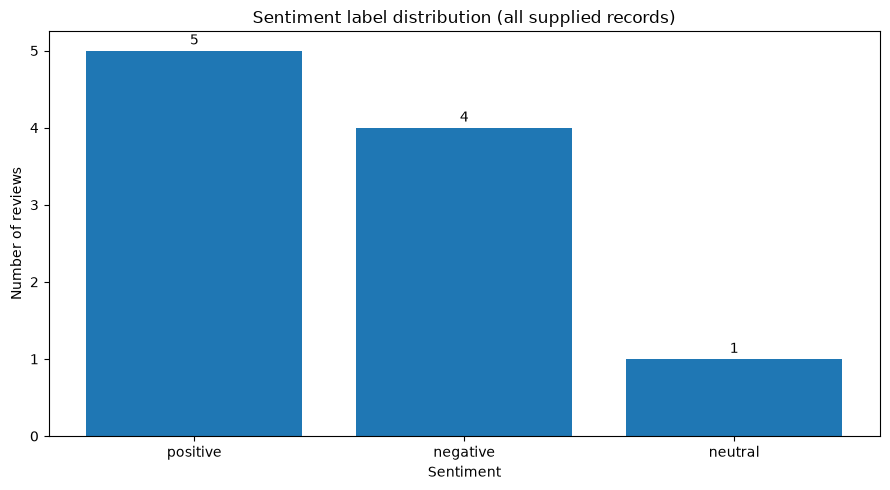

In [5]:
label_counts = df[TARGET_COLUMN].value_counts().reindex(["positive", "negative", "neutral"]).fillna(0).astype(int)
label_summary = pd.DataFrame({"count": label_counts, "percentage": 100 * label_counts / len(df)})
display(label_summary)
fig, ax = plt.subplots()
ax.bar(label_summary.index, label_summary["count"])
ax.set(title="Sentiment label distribution (all supplied records)", xlabel="Sentiment", ylabel="Number of reviews")
for i, value in enumerate(label_summary["count"]):
    ax.text(i, value + 0.08, str(value), ha="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_sentiment_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 1 — Sentiment distribution.** The chart shows five positive, four negative, and one neutral review. The data is not severely imbalanced between the two requested binary classes, but neutral is represented by only one record. A supervised three-class estimate would be impossible to validate responsibly from one neutral observation. The notebook therefore preserves neutral in descriptive analysis and excludes it from the binary training subset rather than inventing additional neutral examples.

## 7. Review length analysis

,review_id,sentiment,word_count,character_count
0,1,positive,9,65
1,2,negative,9,66
2,3,neutral,10,68
3,4,positive,10,66
4,5,negative,10,73
5,6,positive,10,69
6,7,negative,10,60
7,8,positive,9,72
8,9,negative,9,61
9,10,positive,9,63


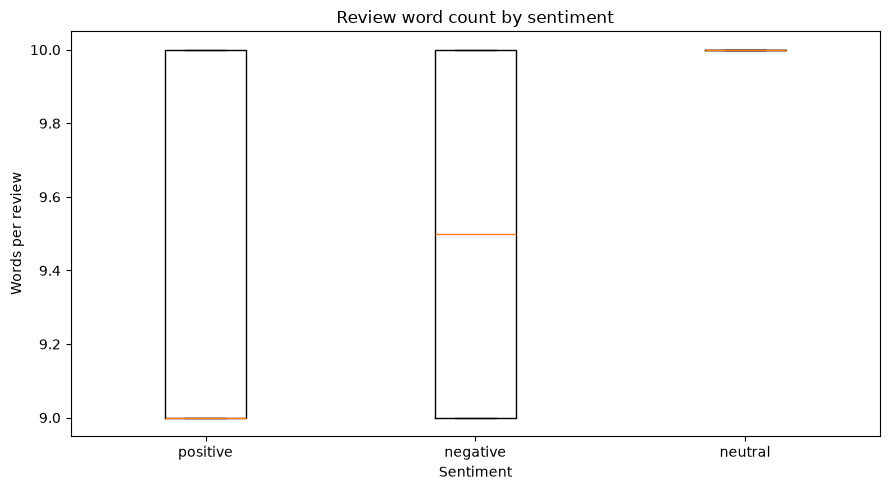

In [8]:
df["word_count"] = df[TEXT_COLUMN].str.split().str.len()
df["character_count"] = df[TEXT_COLUMN].str.len()
display(df[[ID_COLUMN, TARGET_COLUMN, "word_count", "character_count"]])
fig, ax = plt.subplots()
labels = ["positive", "negative", "neutral"]
length_groups = [df.loc[df[TARGET_COLUMN] == label, "word_count"].values for label in labels]
# Matplotlib 3.9+ uses `tick_labels`; older releases use `labels`.
try:
    ax.boxplot(length_groups, tick_labels=labels)
except TypeError:
    ax.boxplot(length_groups, labels=labels)
ax.set(title="Review word count by sentiment", xlabel="Sentiment", ylabel="Words per review")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_review_length_by_sentiment.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 2 — Review length by sentiment.** This plot compares the number of whitespace-delimited words in each class. With five, four, and one observations, the boxes are descriptive only; the singleton neutral category has no meaningful distribution. Differences in review length must not be interpreted as a sentiment signal or population-level finding.

## 8. Text preprocessing

The preprocessing routine decodes HTML entities, removes HTML tags, lowercases, expands a common negation contraction pattern, tokenizes with NLTK `RegexpTokenizer`, removes stopwords, and preserves negation words (`no`, `not`, `nor`, `never`). If the NLTK WordNet corpus is present, it applies `WordNetLemmatizer`; otherwise it uses a documented offline fallback without lemmatization. Preserving negation is important: removing “not” can reverse the meaning of a review.

In [9]:
df["clean_text"] = df[TEXT_COLUMN].map(preprocess_text)
display(df[[ID_COLUMN, TARGET_COLUMN, TEXT_COLUMN, "clean_text"]])
print("Empty cleaned reviews:", (df["clean_text"].str.strip() == "").sum())

,review_id,sentiment,review_text,clean_text
0,1,positive,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectations
1,2,negative,Terrible customer service and the item arrived...,terrible customer service item arrived complet...
2,3,neutral,"Average performance, decent for the price poin...",average performance decent price point nothing...
3,4,positive,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust works flawle...
4,5,negative,Stopped working after two days. Extremely disa...,stopped working two days extremely disappointe...
5,6,positive,Customer support helped resolve my setup quest...,customer support helped resolve setup question...
6,7,negative,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable
7,8,positive,Clean interface and intuitive controls. Highly...,clean interface intuitive controls highly reco...
8,9,negative,"Not worth the money, plenty of better alternat...",not worth money plenty better alternatives ava...
9,10,positive,Great value and durable build. Would definitel...,great value durable build definitely purchase


Empty cleaned reviews: 0


**Preprocessing check.** Compare the raw and cleaned text row by row. HTML markup and punctuation are removed, text is lowercased, common function words are filtered, and negation is intentionally retained. This is a transparent, light preprocessing pipeline appropriate for a very small dataset; more aggressive normalization could remove useful sentiment cues.

## 9. Vocabulary exploration

Binary training records: 9
Binary class counts:


,count
sentiment,
positive,5
negative,4


,token,count
0,customer,2
1,setup,2
2,purchase,2
3,product,1
4,quality,1
5,exceptional,1
6,exceeded,1
7,expectations,1
8,terrible,1
9,service,1


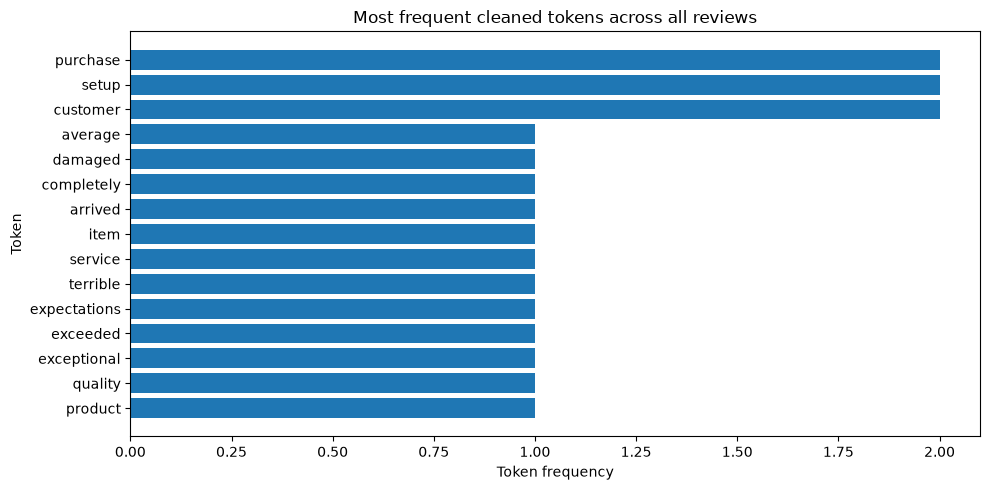

In [10]:
binary_df = binary_training_data(df)
print("Binary training records:", len(binary_df))
print("Binary class counts:")
display(binary_df[TARGET_COLUMN].value_counts().rename_axis("sentiment").to_frame("count"))
all_tokens = [token for text in df["clean_text"] for token in text.split()]
token_counts = Counter(all_tokens)
top_tokens = pd.DataFrame(token_counts.most_common(15), columns=["token", "count"])
display(top_tokens)
fig, ax = plt.subplots(figsize=(10, 5))
plot_tokens = top_tokens.sort_values("count")
ax.barh(plot_tokens["token"], plot_tokens["count"])
ax.set(title="Most frequent cleaned tokens across all reviews", xlabel="Token frequency", ylabel="Token")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_top_token_frequency.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 3 — Most frequent tokens.** The chart describes the vocabulary in this exact ten-review sample. Repeated generic or domain terms may appear frequently, but token frequency alone does not indicate predictive usefulness. In particular, the data is too small to infer broad customer language patterns.

## 10. Positive versus negative vocabulary

,token,positive_count,negative_count,total
39,purchase,1,1,2
11,customer,1,1,2
46,setup,2,0,2
0,absolutely,1,0,1
44,robust,1,0,1
32,missing,0,1,1
33,money,0,1,1
34,not,0,1,1
35,one,0,1,1
36,package,0,1,1


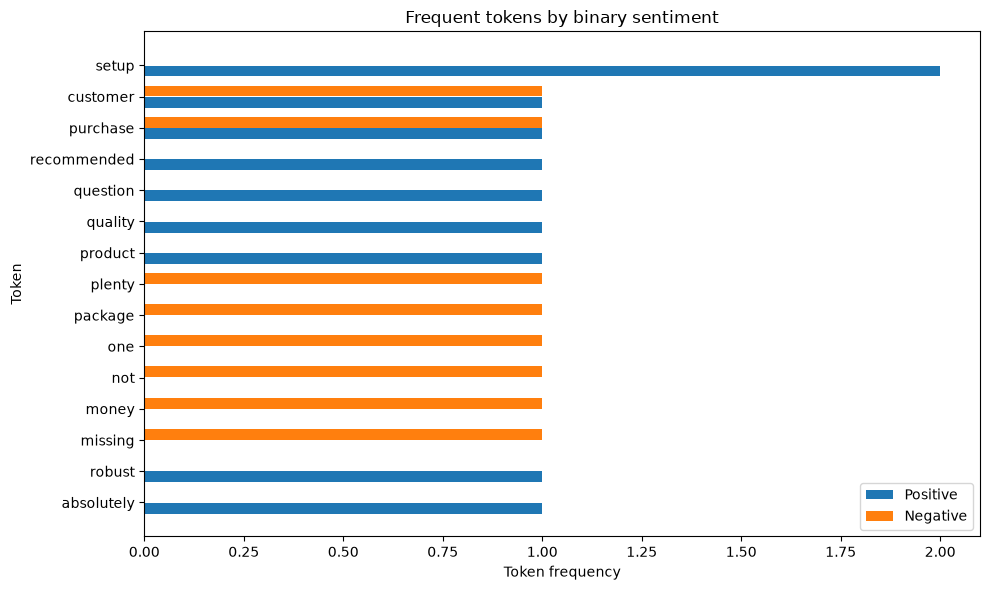

In [11]:
class_token_counts = {}
for label in ("positive", "negative"):
    tokens = [token for text in binary_df.loc[binary_df[TARGET_COLUMN] == label, "clean_text"] for token in text.split()]
    class_token_counts[label] = Counter(tokens)
comparison_tokens = sorted(set(class_token_counts["positive"]) | set(class_token_counts["negative"]))
comparison = pd.DataFrame({
    "token": comparison_tokens,
    "positive_count": [class_token_counts["positive"][t] for t in comparison_tokens],
    "negative_count": [class_token_counts["negative"][t] for t in comparison_tokens],
})
comparison["total"] = comparison["positive_count"] + comparison["negative_count"]
comparison = comparison.sort_values("total", ascending=False).head(15).sort_values("total")
display(comparison.sort_values("total", ascending=False))
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(comparison))
ax.barh(y - 0.18, comparison["positive_count"], height=0.35, label="Positive")
ax.barh(y + 0.18, comparison["negative_count"], height=0.35, label="Negative")
ax.set_yticks(y, comparison["token"])
ax.set(title="Frequent tokens by binary sentiment", xlabel="Token frequency", ylabel="Token")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_class_token_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 4 — Class-specific token counts.** This chart shows which words occur in positive and negative reviews in the supplied sample. Some terms will appear in only one class simply because the corpus has so few documents. These are examples for inspection, not stable sentiment lexicons; a larger and more diverse review corpus is required before interpreting class-associated terms as general patterns.

## 11. Bigram exploration

,bigram,count
0,product quality,1
1,quality exceptional,1
2,exceptional exceeded,1
3,exceeded expectations,1
4,terrible customer,1
5,customer service,1
6,service item,1
7,item arrived,1
8,arrived completely,1
9,completely damaged,1


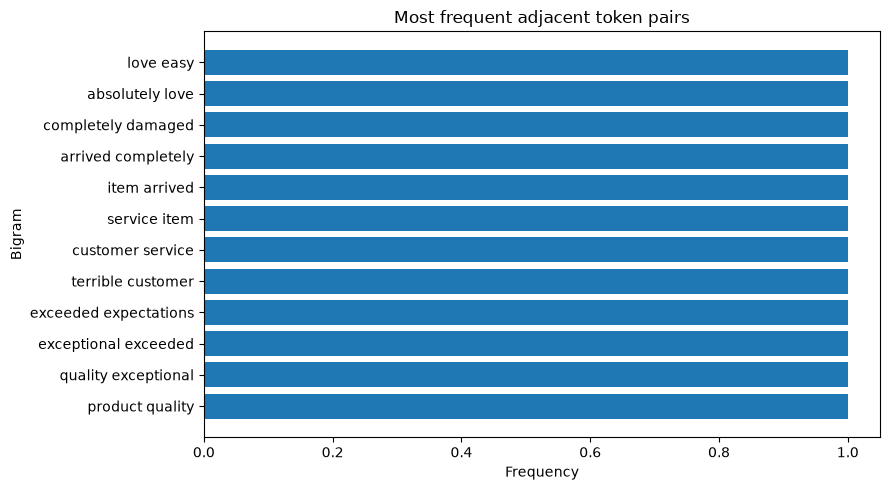

In [12]:
from nltk.util import bigrams
bigram_counts = Counter()
for text in binary_df["clean_text"]:
    bigram_counts.update([" ".join(pair) for pair in bigrams(text.split())])
top_bigrams = pd.DataFrame(bigram_counts.most_common(12), columns=["bigram", "count"])
display(top_bigrams)
fig, ax = plt.subplots(figsize=(9, 5))
if not top_bigrams.empty:
    ordered = top_bigrams.sort_values("count")
    ax.barh(ordered["bigram"], ordered["count"])
ax.set(title="Most frequent adjacent token pairs", xlabel="Frequency", ylabel="Bigram")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_top_bigrams.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 5 — Frequent bigrams.** Bigrams retain short phrases such as “highly recommended” or “extremely disappointed” that can carry more polarity information than individual words. Because most phrases occur once in this tiny corpus, the plot is a qualitative vocabulary audit rather than evidence of robust n-gram patterns.

## 12. TF–IDF representation

`TfidfVectorizer(max_features=5000)` maps cleaned text to a sparse document-term matrix. The vectorizer is fitted only inside each cross-validation training fold when evaluating the models. A separate vectorizer is fitted below only for descriptive inspection of the full binary-labelled sample; those descriptive weights are not used to calculate validation metrics.

TF-IDF matrix shape: (9, 112)
Number of TF-IDF features: 112
Sparse matrix density: 0.11408730158730158


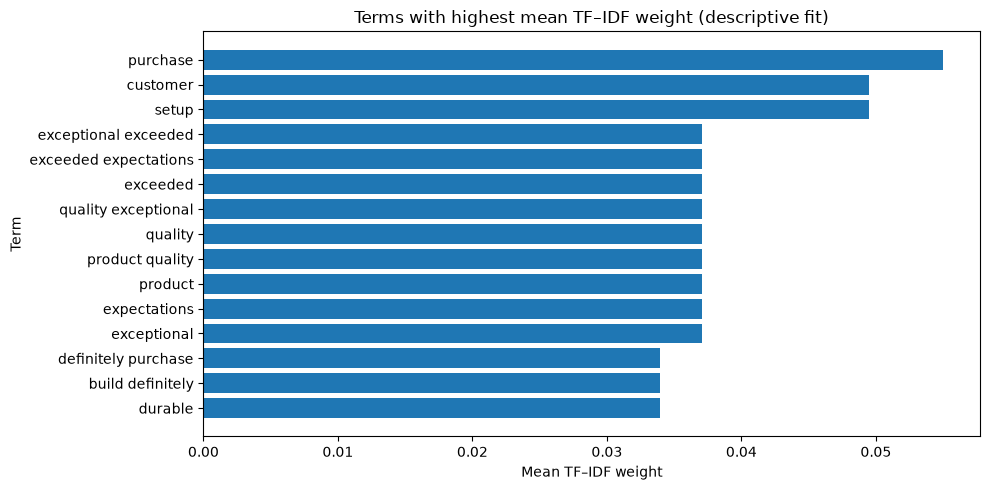

In [13]:
descriptive_vectorizer = build_vectorizer()
X_tfidf_descriptive = descriptive_vectorizer.fit_transform(binary_df[TEXT_COLUMN])
feature_names_descriptive = descriptive_vectorizer.get_feature_names_out()
print("TF-IDF matrix shape:", X_tfidf_descriptive.shape)
print("Number of TF-IDF features:", len(feature_names_descriptive))
print("Sparse matrix density:", X_tfidf_descriptive.nnz / (X_tfidf_descriptive.shape[0] * X_tfidf_descriptive.shape[1]))
mean_tfidf = np.asarray(X_tfidf_descriptive.mean(axis=0)).ravel()
tfidf_top_idx = np.argsort(mean_tfidf)[-15:]
tfidf_top = pd.DataFrame({"term": feature_names_descriptive[tfidf_top_idx], "mean_tfidf": mean_tfidf[tfidf_top_idx]}).sort_values("mean_tfidf")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(tfidf_top["term"], tfidf_top["mean_tfidf"])
ax.set(title="Terms with highest mean TF–IDF weight (descriptive fit)", xlabel="Mean TF–IDF weight", ylabel="Term")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_mean_tfidf_terms.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 6 — Mean TF–IDF term weights.** TF–IDF increases the weight of terms that are informative within a document relative to the corpus. This chart summarizes weights across the nine binary-labelled reviews. It is not a ranking of causal drivers or a globally valid vocabulary; terms can receive high weights because they occur in only one short review.

## 13. Cross-validation design and model training

We use `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)` on the nine positive/negative records. Each review receives an out-of-fold prediction from a model that did not train on that review. `TfidfVectorizer` remains inside the pipeline so each fold builds its own vocabulary and IDF statistics. The comparison includes accuracy, positive-class precision/recall/F1, ROC-AUC, and average precision. Due to sample size, each metric can change substantially if even one review changes.

In [14]:
metrics, oof_predictions, final_models = evaluate_with_oof(binary_df, n_splits=3)
display(metrics.round(3))
display(oof_predictions[[ID_COLUMN, TARGET_COLUMN,
    "multinomial_nb_prediction", "logistic_regression_prediction"]])
metrics.to_csv(REPORT_DIR / "cross_validation_metrics.csv", index=False)
oof_predictions.to_csv(REPORT_DIR / "out_of_fold_predictions.csv", index=False)

,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,multinomial_nb,0.444,0.5,0.4,0.444,0.35,0.511
1,logistic_regression,0.444,0.5,0.4,0.444,0.30,0.511


,review_id,sentiment,multinomial_nb_prediction,logistic_regression_prediction
0,1,positive,negative,negative
1,2,negative,negative,negative
2,4,positive,positive,positive
3,5,negative,positive,positive
4,6,positive,positive,positive
5,7,negative,negative,negative
6,8,positive,negative,negative
7,9,negative,positive,positive
8,10,positive,negative,negative


## 14. Accuracy benchmark

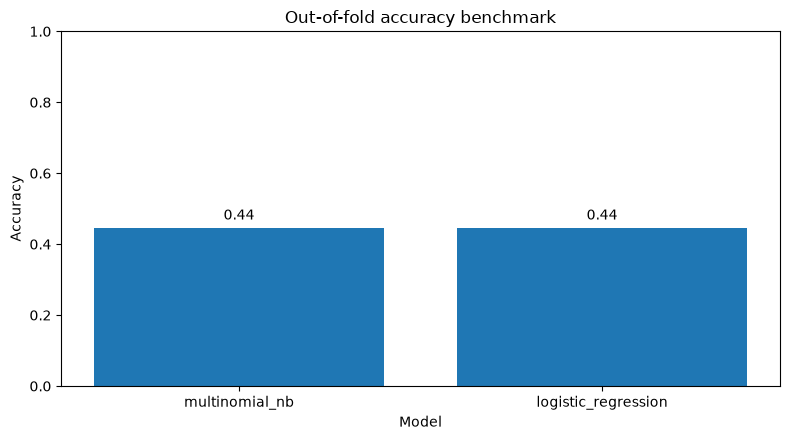

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_metrics = metrics.sort_values("accuracy")
ax.bar(plot_metrics["model"], plot_metrics["accuracy"])
ax.set_ylim(0, 1)
ax.set(title="Out-of-fold accuracy benchmark", xlabel="Model", ylabel="Accuracy")
for i, value in enumerate(plot_metrics["accuracy"]):
    ax.text(i, value + 0.025, f"{value:.2f}", ha="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_accuracy_benchmark.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 7 — Accuracy benchmark.** Accuracy is the share of the nine out-of-fold examples classified correctly. With nine examples, one mistake changes accuracy by 11.1 percentage points. The bar chart is included because the task requests accuracy benchmarks, but it must be read alongside class-sensitive metrics and the sample-size warning.

## 15. Precision, recall, F1, ROC-AUC and average precision

metric,average_precision,f1,precision,recall,roc_auc
model,,,,,
logistic_regression,0.511,0.444,0.5,0.4,0.30
multinomial_nb,0.511,0.444,0.5,0.4,0.35


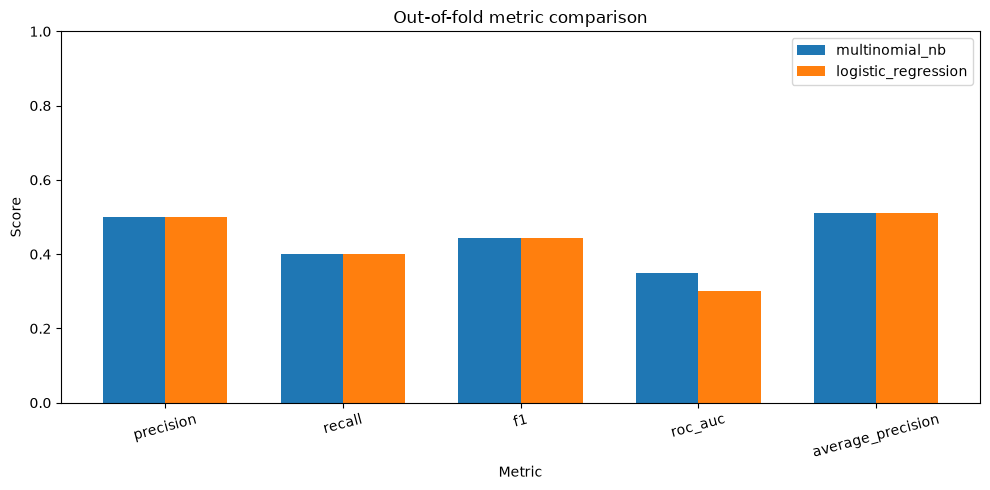

In [16]:
metric_columns = ["precision", "recall", "f1", "roc_auc", "average_precision"]
metric_long = metrics.melt(id_vars="model", value_vars=metric_columns,
                           var_name="metric", value_name="score")
display(metric_long.pivot(index="model", columns="metric", values="score").round(3))
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(metric_columns))
width = 0.35
for j, (_, row) in enumerate(metrics.set_index("model").iterrows()):
    ax.bar(x + (j - 0.5) * width, [row[c] for c in metric_columns], width, label=row.name)
ax.set_xticks(x, metric_columns, rotation=15)
ax.set_ylim(0, 1)
ax.set(title="Out-of-fold metric comparison", ylabel="Score", xlabel="Metric")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "08_metric_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 8 — Metric comparison.** Precision measures how many reviews predicted positive are actually positive; recall measures how many positive reviews are recovered; F1 balances those two. ROC-AUC summarizes ranking across thresholds, while average precision emphasizes performance on the positive class. Do not select a model from a small numerical difference in this nine-example sample.

## 16. Confusion matrices from out-of-fold predictions

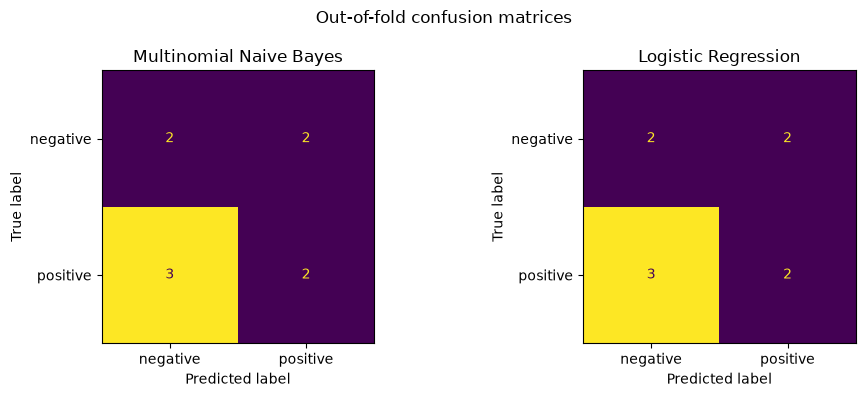

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, column in zip(axes,
    ["Multinomial Naive Bayes", "Logistic Regression"],
    ["multinomial_nb_prediction", "logistic_regression_prediction"]):
    cm = confusion_matrix(binary_df[TARGET_COLUMN], oof_predictions[column], labels=["negative", "positive"])
    ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
fig.suptitle("Out-of-fold confusion matrices")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 9 — Confusion matrices.** Rows are actual labels and columns are predicted labels, ordered negative then positive. The diagonal cells are correct classifications; off-diagonal cells are errors. Because all predictions are out-of-fold, each displayed result was generated without fitting on that review. The tiny test count means every cell represents only a handful of examples.

## 17. ROC curve

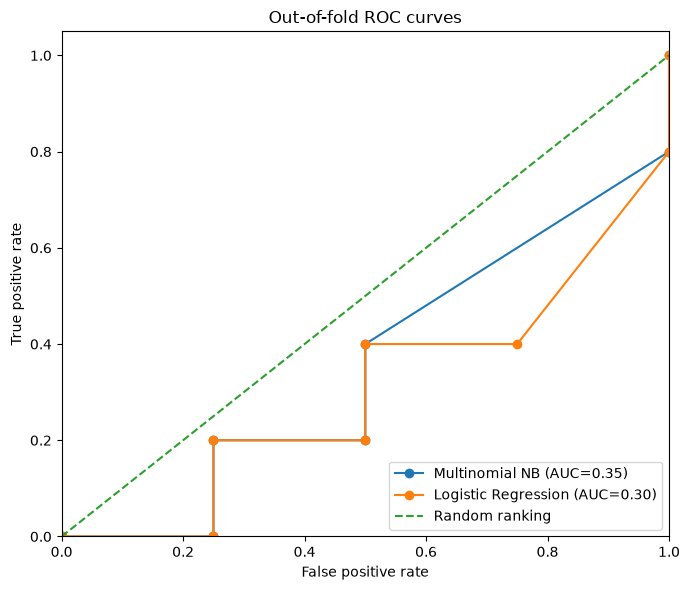

In [18]:
y_binary = (binary_df[TARGET_COLUMN].to_numpy() == "positive").astype(int)
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, prob_col, label in [
    ("multinomial_nb", "multinomial_nb_positive_probability", "Multinomial NB"),
    ("logistic_regression", "logistic_regression_positive_probability", "Logistic Regression"),
]:
    fpr, tpr, _ = roc_curve(y_binary, oof_predictions[prob_col])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, marker="o", label=f"{label} (AUC={roc_auc:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
ax.set(xlim=(0, 1), ylim=(0, 1.05), title="Out-of-fold ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 10 — ROC curves.** The ROC curve plots true-positive rate against false-positive rate across decision thresholds. The dashed diagonal is the random-ranking reference. The AUC shown is calculated from out-of-fold positive probabilities. With only nine labels, the curve has very few distinct operating points and its AUC is highly uncertain; it should not be treated as a deployment guarantee.

## 18. Precision–recall curves

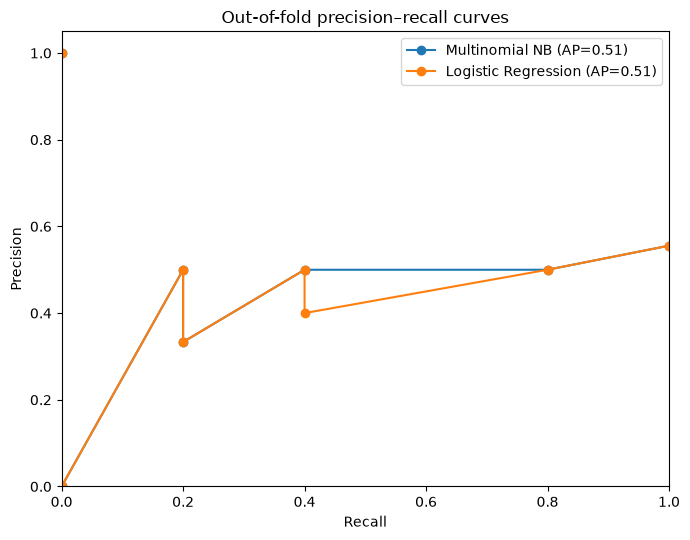

In [19]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for model_name, prob_col, label in [
    ("multinomial_nb", "multinomial_nb_positive_probability", "Multinomial NB"),
    ("logistic_regression", "logistic_regression_positive_probability", "Logistic Regression"),
]:
    precision, recall, _ = precision_recall_curve(y_binary, oof_predictions[prob_col])
    ap = average_precision_score(y_binary, oof_predictions[prob_col])
    ax.plot(recall, precision, marker="o", label=f"{label} (AP={ap:.2f})")
ax.set(xlim=(0, 1), ylim=(0, 1.05), title="Out-of-fold precision–recall curves", xlabel="Recall", ylabel="Precision")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "11_precision_recall_curves.png", dpi=160, bbox_inches="tight")
plt.show()

**Plot 11 — Precision–recall curves.** This view focuses on the positive class and shows the trade-off between recovering positive reviews and avoiding false positive labels. Average precision summarizes the curve. It is often useful when classes are imbalanced, but this sample is small and only mildly imbalanced between the binary classes; the chart is a teaching diagnostic rather than a stable model-selection basis.

## 19. Logistic Regression: influential TF–IDF terms

,term,coefficient,direction
0,extremely,-0.127224,negative
8,stopped working,-0.127224,negative
7,days extremely,-0.127224,negative
6,disappointed,-0.127224,negative
5,disappointed purchase,-0.127224,negative
9,stopped,-0.127224,negative
3,two days,-0.127224,negative
2,working,-0.127224,negative
1,working two,-0.127224,negative
4,two,-0.127224,negative


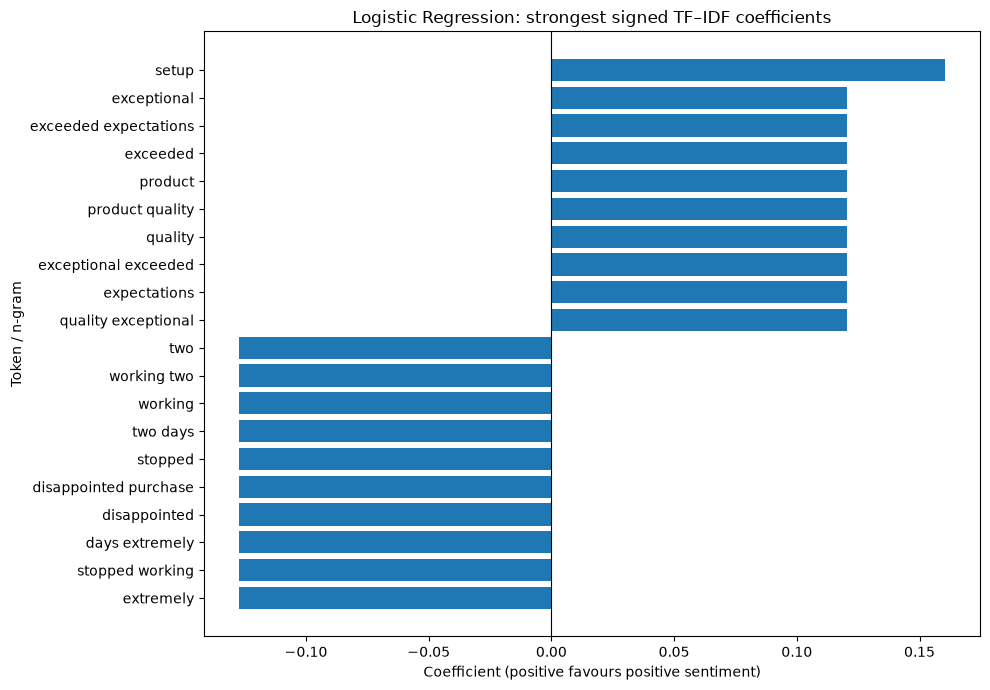

In [20]:
lr_model = final_models["logistic_regression"]
lr_vectorizer = lr_model.named_steps["tfidf"]
lr_classifier = lr_model.named_steps["classifier"]
lr_terms = lr_vectorizer.get_feature_names_out()
lr_coef = lr_classifier.coef_[0]
negative_idx = np.argsort(lr_coef)[:10]
positive_idx = np.argsort(lr_coef)[-10:]
coef_frame = pd.concat([
    pd.DataFrame({"term": lr_terms[negative_idx], "coefficient": lr_coef[negative_idx], "direction": "negative"}),
    pd.DataFrame({"term": lr_terms[positive_idx], "coefficient": lr_coef[positive_idx], "direction": "positive"}),
], ignore_index=True)
display(coef_frame.sort_values("coefficient"))
fig, ax = plt.subplots(figsize=(10, 7))
ordered = coef_frame.sort_values("coefficient")
ax.barh(ordered["term"], ordered["coefficient"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Logistic Regression: strongest signed TF–IDF coefficients", xlabel="Coefficient (positive favours positive sentiment)", ylabel="Token / n-gram")
fig.tight_layout()
fig.savefig(FIG_DIR / "12_logistic_regression_terms.png", dpi=160, bbox_inches="tight")
plt.show()
coef_frame.to_csv(REPORT_DIR / "logistic_regression_top_terms.csv", index=False)

**Plot 12 — Logistic Regression token coefficients.** Positive coefficients push the decision towards the positive class; negative coefficients push it towards negative. These are model associations, not causal explanations. With only nine training examples, a token occurring in one review can receive an extreme coefficient. Treat these terms as examples of how a linear TF–IDF classifier can be inspected, not as general customer sentiment drivers.

## 20. Multinomial Naive Bayes: class-associated terms

,term,positive_minus_negative_log_probability
0,item arrived,-0.272395
8,extremely disappointed,-0.272395
7,customer service,-0.272395
6,damaged,-0.272395
5,days,-0.272395
9,completely damaged,-0.272395
3,disappointed,-0.272395
2,disappointed purchase,-0.272395
1,item,-0.272395
4,days extremely,-0.272395


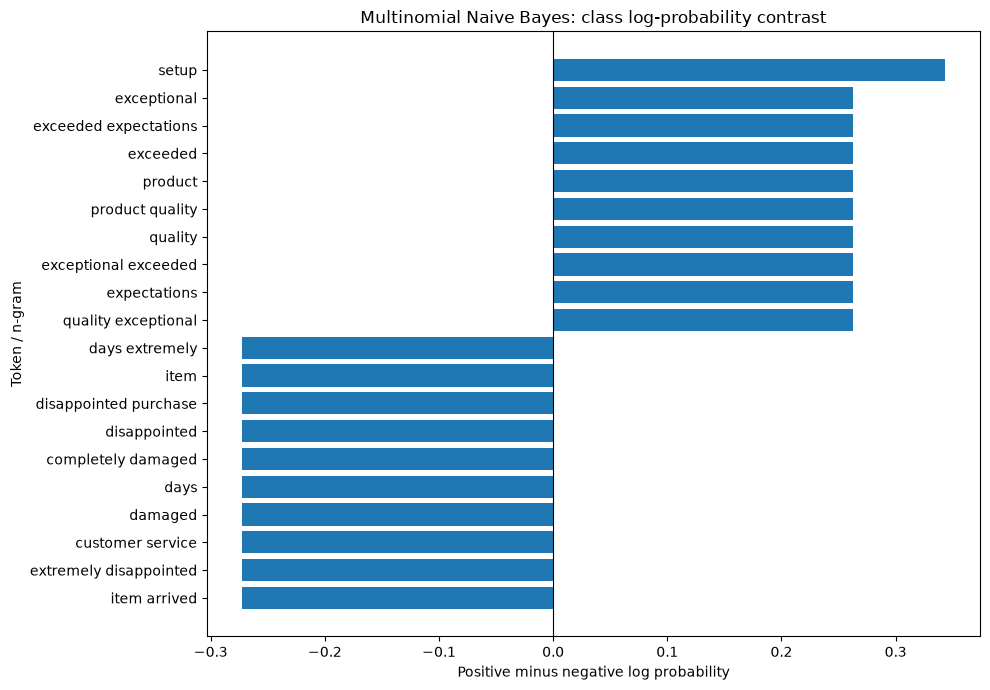

In [21]:
nb_model = final_models["multinomial_nb"]
nb_vectorizer = nb_model.named_steps["tfidf"]
nb_classifier = nb_model.named_steps["classifier"]
nb_terms = nb_vectorizer.get_feature_names_out()
class_names = list(nb_classifier.classes_)
neg_i, pos_i = class_names.index("negative"), class_names.index("positive")
nb_log_ratio = nb_classifier.feature_log_prob_[pos_i] - nb_classifier.feature_log_prob_[neg_i]
nb_neg_idx = np.argsort(nb_log_ratio)[:10]
nb_pos_idx = np.argsort(nb_log_ratio)[-10:]
nb_terms_frame = pd.concat([
    pd.DataFrame({"term": nb_terms[nb_neg_idx], "positive_minus_negative_log_probability": nb_log_ratio[nb_neg_idx]}),
    pd.DataFrame({"term": nb_terms[nb_pos_idx], "positive_minus_negative_log_probability": nb_log_ratio[nb_pos_idx]}),
], ignore_index=True)
display(nb_terms_frame.sort_values("positive_minus_negative_log_probability"))
fig, ax = plt.subplots(figsize=(10, 7))
ordered = nb_terms_frame.sort_values("positive_minus_negative_log_probability")
ax.barh(ordered["term"], ordered["positive_minus_negative_log_probability"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Multinomial Naive Bayes: class log-probability contrast", xlabel="Positive minus negative log probability", ylabel="Token / n-gram")
fig.tight_layout()
fig.savefig(FIG_DIR / "13_naive_bayes_terms.png", dpi=160, bbox_inches="tight")
plt.show()
nb_terms_frame.to_csv(REPORT_DIR / "naive_bayes_top_terms.csv", index=False)

**Plot 13 — Naive Bayes class-associated terms.** The horizontal axis is the difference between the learned positive and negative class-conditional log probabilities for each TF–IDF feature. Positive values are more associated with the positive class in this fitted sample; negative values are more associated with negative. These weights are estimated from only nine reviews and should not be generalized.

## 21. Final pipeline fit and model persistence

In [22]:
save_models(final_models, MODEL_DIR)
print("Saved model artifacts:")
for model_path in sorted(MODEL_DIR.glob("*.joblib")):
    print(" -", model_path.name, f"({model_path.stat().st_size:,} bytes)")

Saved model artifacts:
 - logistic_regression.joblib (7,316 bytes)
 - multinomial_nb.joblib (9,825 bytes)


Both final pipelines are fitted on all nine positive/negative examples after the out-of-fold benchmark. The saved files are convenience artefacts for reproducing the demonstration. They are not production-ready because the training corpus is extremely small and does not include a learnable neutral class.

## 22. Interactive custom phrase prediction

The helper function accepts a single string or a list of strings. It returns the predicted binary label, the maximum class probability (confidence), and the estimated positive probability. Confidence is not a calibrated certainty score, especially with this tiny dataset. Run your own phrases in the cell below.

In [23]:
def predict_sentiment(text, model_name="logistic_regression"):
    """Predict polarity for custom text with a fitted project model."""
    if model_name not in final_models:
        raise ValueError("model_name must be 'multinomial_nb' or 'logistic_regression'")
    if isinstance(text, str) and not text.strip():
        raise ValueError("Please provide a non-empty review phrase")
    return __import__("sentiment_pipeline").predict_sentiment(text, final_models[model_name])

sample_phrases = [
    "The product is excellent and works perfectly.",
    "Terrible quality and very disappointing experience.",
    "Not worth the money and stopped working.",
    "Great value, easy to use, and highly recommended.",
]
display(predict_sentiment(sample_phrases, model_name="logistic_regression"))

,review_text,predicted_sentiment,confidence,positive_probability
0,The product is excellent and works perfectly.,positive,0.549057,0.549057
1,Terrible quality and very disappointing experi...,positive,0.509020,0.509020
2,Not worth the money and stopped working.,negative,0.577933,0.422067
3,"Great value, easy to use, and highly recommended.",positive,0.579107,0.579107


## 23. Conclusions and recommendations

### What was implemented

- A validated ingestion step for the supplied `review_id`, `review_text`, and `sentiment` columns.
- NLTK-based tokenization and stopword filtering, with negation preservation and conditional WordNet lemmatization.
- A fold-safe TF–IDF representation with `max_features=5000` and unigrams/bigrams.
- Multinomial Naive Bayes and Logistic Regression pipelines.
- Stratified 3-fold out-of-fold accuracy, precision, recall, F1, ROC-AUC, and average-precision benchmarks.
- Thirteen figures and per-plot interpretations, including class distribution, length, vocabulary, confusion matrices, ROC/PR curves, and interpretable term weights.
- A live custom-text helper function and saved model pipelines.

### Limitations

1. **Very small dataset:** 10 total rows, and only nine binary-labelled examples. CV metrics are unstable.
2. **Neutral label excluded from fitting:** one neutral review is insufficient to train or evaluate a neutral class. The current helper only predicts positive or negative.
3. **Domain coverage:** the ten short reviews do not represent the diversity of real product or movie reviews.
4. **Confidence calibration:** probabilities from such a tiny sample should not be interpreted as trustworthy confidence estimates.
5. **Preprocessing resources:** WordNet lemmatization is enabled when the NLTK WordNet corpus is available; otherwise the documented offline fallback skips lemmatization.

### Next steps for a credible model

Collect at least hundreds or preferably thousands of labelled reviews with balanced coverage of positive, negative, and neutral sentiments; use a held-out test set; report confidence intervals and class-wise metrics; inspect false positives/negatives; and validate the chosen threshold on real deployment data. Keep the TF–IDF transform inside the pipeline to avoid leakage.

**Final takeaway:** this repository demonstrates the required classical NLP workflow correctly on the exact supplied CSV. It is a pipeline demonstration, not evidence of production-grade sentiment prediction.